# CSCIE89 : Vanilla PyTorch program

**Model looks at a handwritten digit and predict which number it is (0–9).**

We will use one dataset and one neural network throughout this notebook:

Our Steps:

        Load images 
        split data 
        build model 
        train model 
        test model 
        predict one image 

We will use scikit-learn's built-in **8×8 digits** instead of Fashion-MNIST, so no dataset download is needed. We use a small fully connected network, not a CNN. We also include training and testing so you can see the complete process.

This **DOES NOT** USE a CNN.

## 1. Import the tools

PyTorch builds and trains the model. Scikit-learn provides the images and splits them into two groups. Matplotlib lets us see an image.

If the imports fail, uncomment the installation line, run it once, then restart the notebook. This small program runs on the CPU; no GPU setup is needed.

In [1]:
# %pip install torch scikit-learn matplotlib

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

torch.manual_seed(42)  # Helps make the results repeatable.

## 2. Load the images and their answers

Each image is an 8×8 grid of brightness values. Its label is the correct digit. The first dimension counts images: `(1797, 8, 8)` means 1,797 images, each 8 pixels high and 8 pixels wide.

We convert the images to floating-point PyTorch **tensors** (arrays). Dividing by 16 changes the pixel range from 0–16 to 0–1. Labels are integer tensors because they represent class numbers.In load_digits(), pixel brightness ranges from 0 to 16:
- 0 = black
- 16 = white
- Values between them = shades of gray
Dividing by 16 scales those values to 0–1:

Image tensor shape: torch.Size([1797, 8, 8])
First image label: 0


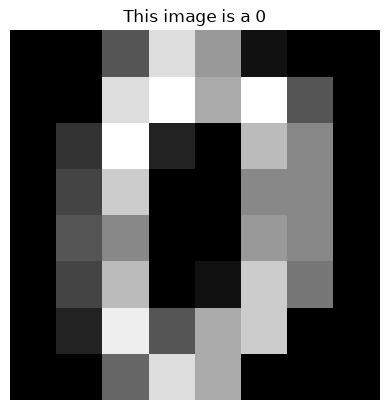

In [2]:
digits = load_digits()

images = torch.tensor(digits.images, dtype=torch.float32) / 16.0
labels = torch.tensor(digits.target, dtype=torch.long)

print('Image tensor shape:', images.shape)
print('First image label:', labels[0].item())

plt.imshow(images[0], cmap='gray')
plt.title(f'This image is a {labels[0].item()}')
plt.axis('off')
plt.show()

## 3. Separate learning data from testing data

The model learns from **80%** of the images. We keep the other **20%** for testing after training. `stratify` keeps similar proportions of the digits in both groups.

`TensorDataset` pairs each training image with its answer. `DataLoader` gives the training loop 64 pairs at a time. This small group is called a **batch**. Shuffling changes the training order each time through the data.

In [3]:
train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels,
    test_size=0.20,
    random_state=42,
    stratify=labels,
)

train_dataset = TensorDataset(train_images, train_labels)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

print('Training images:', len(train_images))
print('Test images:', len(test_images))

Training images: 1437
Test images: 360


## 4. Build our one model

`nn.Sequential` connects the layers in order:

- **Flatten:** turns each 8×8 image into a list of 64 numbers, keeping images separate.
- **Linear(64, 64):** learns 64 combinations of those pixel values.
- **ReLU:** replaces negative values with zero, allowing the network to learn nonlinear patterns.
- **Linear(64, 10):** produces one score for each possible digit.

For a batch of images, the shape changes are `(batch, 8, 8) → (batch, 64) → (batch, 64) → (batch, 10)`.

The model starts with random weights. Calling `model(images)` runs the images through all these layers. We use Sequential directly here, so a custom class and a separate `forward` method are unnecessary.

In [4]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=10, bias=True)
)


## 5. Choose how the model learns

The **loss function** measures how wrong the model's scores are compared with the correct labels. The **optimizer** adjusts the model's weights to reduce that loss.

`CrossEntropyLoss` is suitable when each image belongs to one class. It takes the raw scores, called logits, so we do not add softmax. Adam uses the gradients calculated during training to update the weights. Its learning rate controls the size of the updates.

In [5]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 6. Train the model

An **epoch** is one complete pass through all training images. We make 20 passes. For every batch, we predict the digits, calculate the loss, calculate gradients, and update the weights.

Gradients tell the optimizer how changes to the weights affect the loss. `zero_grad()` clears gradients left over from the previous batch. `backward()` calculates new gradients. **`optimizer.step()` is the line that changes the weights.**

The average loss printed below should generally decrease. The test images do not appear in this loop.

In [6]:
epochs = 20
model.train()  # Put the model in training mode.

for epoch in range(epochs):
    total_loss = 0.0

    for batch_images, batch_labels in train_loader:
        optimizer.zero_grad()                         # Clear old gradients.
        scores = model(batch_images)                  # Predict this batch.
        loss = loss_function(scores, batch_labels)    # Measure the error.
        loss.backward()                               # Calculate gradients.
        optimizer.step()                              # Update the weights.

        # Weight each batch's average loss by the number of images in it.
        total_loss += loss.item() * len(batch_images)

    average_loss = total_loss / len(train_dataset)
    print(f'Epoch {epoch + 1:2d}/{epochs} | Loss: {average_loss:.4f}')

Epoch  1/20 | Loss: 2.2367
Epoch  2/20 | Loss: 2.0544
Epoch  3/20 | Loss: 1.7957
Epoch  4/20 | Loss: 1.4909
Epoch  5/20 | Loss: 1.1928
Epoch  6/20 | Loss: 0.9500
Epoch  7/20 | Loss: 0.7723
Epoch  8/20 | Loss: 0.6416
Epoch  9/20 | Loss: 0.5469
Epoch 10/20 | Loss: 0.4745
Epoch 11/20 | Loss: 0.4203
Epoch 12/20 | Loss: 0.3750
Epoch 13/20 | Loss: 0.3419
Epoch 14/20 | Loss: 0.3109
Epoch 15/20 | Loss: 0.2873
Epoch 16/20 | Loss: 0.2665
Epoch 17/20 | Loss: 0.2499
Epoch 18/20 | Loss: 0.2379
Epoch 19/20 | Loss: 0.2230
Epoch 20/20 | Loss: 0.2134


## 7. Test the trained model

Now we give the same model images it did not see during training. Each row of scores has ten entries. `argmax(dim=1)` chooses the index of the largest score in each row: that is the predicted digit.

`model.eval()` selects evaluation behavior. `torch.no_grad()` turns off gradient tracking because we are only checking predictions. Neither line changes the learned weights.

**Accuracy = number of correct predictions ÷ number of test images.** We can evaluate all test images together here because this dataset is small.

In [7]:
model.eval()

with torch.no_grad():
    test_scores = model(test_images)
    test_predictions = test_scores.argmax(dim=1)

correct = (test_predictions == test_labels).sum().item()
accuracy = correct / len(test_labels)

print(f'Correct predictions: {correct} out of {len(test_labels)}')
print(f'Test accuracy: {accuracy:.2%}')

Correct predictions: 341 out of 360
Test accuracy: 94.72%


## 8. Look at one prediction

The predictions above follow the same order as the test images. We display the first image with its predicted and actual digit. Change `index` to inspect a different example.

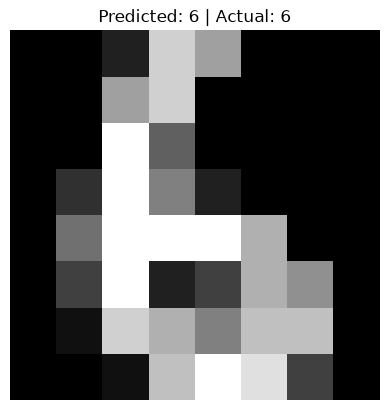

In [9]:
index = 6
predicted_digit = test_predictions[index].item()
actual_digit = test_labels[index].item()

plt.imshow(test_images[index], cmap='gray')
plt.title(f'Predicted: {predicted_digit} | Actual: {actual_digit}')
plt.axis('off')
plt.show()

## Summary : How the pieces fit together

`train_loader` supplies images and labels. `model` produces scores. `loss_function` compares scores with labels. `backward()` computes gradients, and `optimizer.step()` updates that same model. After training, we use the model on `test_images` and compare its answers with `test_labels`.
